- Importing required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

- Load dataset

In [2]:
# Load the dataset
df=pd.read_csv('CarPrice_Assignment.csv')
df.shape

(205, 26)

In [3]:
df.columns

Index(['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration',
       'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase',
       'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype',
       'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke',
       'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg',
       'price'],
      dtype='object')

In [4]:
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [5]:
df[df.duplicated()]#to find if any duplicates are there

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price


 - No duplicate rows present

In [6]:
print('Missing values per column:')
print(df.isnull().sum())

Missing values per column:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64


 - No Missing values

In [7]:
df.dtypes #column datatypes

car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionratio    float64
horsepower            int64
peakrpm               int64
citympg               int64
highwaympg            int64
price               float64
dtype: object

In [8]:
print(df['price'].describe())

count      205.000000
mean     13276.710571
std       7988.852332
min       5118.000000
25%       7788.000000
50%      10295.000000
75%      16503.000000
max      45400.000000
Name: price, dtype: float64


- Visualize the target, understand the price distribution

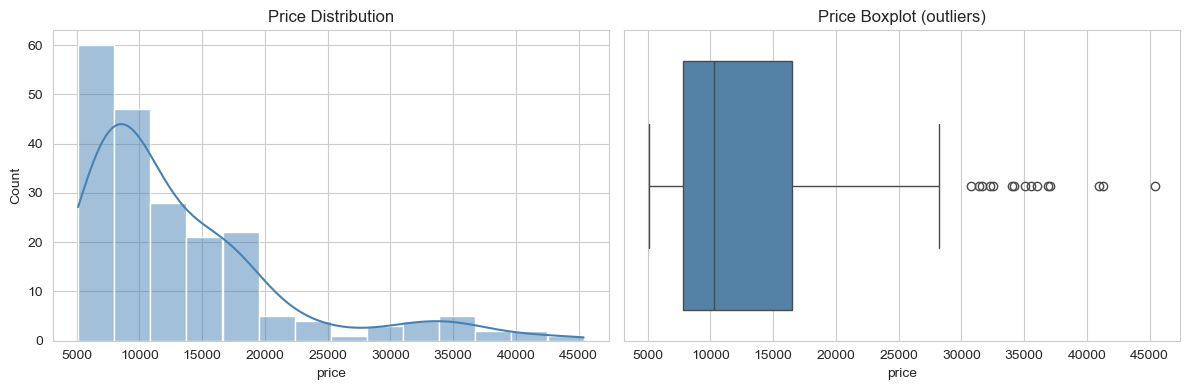

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['price'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Price Distribution')
sns.boxplot(x=df['price'], ax=axes[1], color='steelblue')
axes[1].set_title('Price Boxplot (outliers)')
plt.tight_layout()
plt.show()

In [10]:
data =df.copy() #taking a copy

In [11]:
# Drop columns that are not useful for modeling
# car_ID = just a row index
data = data.drop(columns=['car_ID'])

In [12]:
print(sorted(data['CarName'].unique()))

['Nissan versa', 'alfa-romero Quadrifoglio', 'alfa-romero giulia', 'alfa-romero stelvio', 'audi 100 ls', 'audi 100ls', 'audi 4000', 'audi 5000', 'audi 5000s (diesel)', 'audi fox', 'bmw 320i', 'bmw x1', 'bmw x3', 'bmw x4', 'bmw x5', 'bmw z4', 'buick century', 'buick century luxus (sw)', 'buick century special', 'buick electra 225 custom', 'buick opel isuzu deluxe', 'buick regal sport coupe (turbo)', 'buick skyhawk', 'buick skylark', 'chevrolet impala', 'chevrolet monte carlo', 'chevrolet vega 2300', 'dodge challenger se', 'dodge colt (sw)', 'dodge colt hardtop', 'dodge coronet custom', 'dodge coronet custom (sw)', 'dodge d200', 'dodge dart custom', 'dodge monaco (sw)', 'dodge rampage', 'honda accord', 'honda accord cvcc', 'honda accord lx', 'honda civic', 'honda civic (auto)', 'honda civic 1300', 'honda civic 1500 gl', 'honda civic cvcc', 'honda prelude', 'isuzu D-Max ', 'isuzu D-Max V-Cross', 'isuzu MU-X', 'jaguar xf', 'jaguar xj', 'jaguar xk', 'maxda glc deluxe', 'maxda rx3', 'mazda 6

In [13]:
#data['CarName'].value_counts()

In [14]:
#sns.countplot(x='enginelocation',data=data)
#plt.show()

#for i in data.columns:
#    sns.countplot(x=i,data=data)
#    plt.show()


In [15]:
# Extract company name (first word of CarName)

data['company'] = data['CarName'].str.split().str[0].str.lower()
print(data['company'].to_list())

['alfa-romero', 'alfa-romero', 'alfa-romero', 'audi', 'audi', 'audi', 'audi', 'audi', 'audi', 'audi', 'bmw', 'bmw', 'bmw', 'bmw', 'bmw', 'bmw', 'bmw', 'bmw', 'chevrolet', 'chevrolet', 'chevrolet', 'dodge', 'dodge', 'dodge', 'dodge', 'dodge', 'dodge', 'dodge', 'dodge', 'dodge', 'honda', 'honda', 'honda', 'honda', 'honda', 'honda', 'honda', 'honda', 'honda', 'honda', 'honda', 'honda', 'honda', 'isuzu', 'isuzu', 'isuzu', 'isuzu', 'jaguar', 'jaguar', 'jaguar', 'maxda', 'maxda', 'mazda', 'mazda', 'mazda', 'mazda', 'mazda', 'mazda', 'mazda', 'mazda', 'mazda', 'mazda', 'mazda', 'mazda', 'mazda', 'mazda', 'mazda', 'buick', 'buick', 'buick', 'buick', 'buick', 'buick', 'buick', 'buick', 'mercury', 'mitsubishi', 'mitsubishi', 'mitsubishi', 'mitsubishi', 'mitsubishi', 'mitsubishi', 'mitsubishi', 'mitsubishi', 'mitsubishi', 'mitsubishi', 'mitsubishi', 'mitsubishi', 'mitsubishi', 'nissan', 'nissan', 'nissan', 'nissan', 'nissan', 'nissan', 'nissan', 'nissan', 'nissan', 'nissan', 'nissan', 'nissan', '

In [16]:
sorted(data['company'].unique())

['alfa-romero',
 'audi',
 'bmw',
 'buick',
 'chevrolet',
 'dodge',
 'honda',
 'isuzu',
 'jaguar',
 'maxda',
 'mazda',
 'mercury',
 'mitsubishi',
 'nissan',
 'peugeot',
 'plymouth',
 'porcshce',
 'porsche',
 'renault',
 'saab',
 'subaru',
 'toyota',
 'toyouta',
 'vokswagen',
 'volkswagen',
 'volvo',
 'vw']

In [17]:
# Fix common spelling mistakes / aliases in brand names
brand_fix = {
    'maxda': 'mazda',
    'porcshce': 'porsche',
    'toyouta': 'toyota',
    'vokswagen': 'volkswagen',
    'vw': 'volkswagen',
}
data['company'] = data['company'].replace(brand_fix)
sorted(data['company'].unique())

['alfa-romero',
 'audi',
 'bmw',
 'buick',
 'chevrolet',
 'dodge',
 'honda',
 'isuzu',
 'jaguar',
 'mazda',
 'mercury',
 'mitsubishi',
 'nissan',
 'peugeot',
 'plymouth',
 'porsche',
 'renault',
 'saab',
 'subaru',
 'toyota',
 'volkswagen',
 'volvo']

In [18]:
print(data['company'].value_counts())

company
toyota         32
nissan         18
mazda          17
mitsubishi     13
honda          13
volkswagen     12
subaru         12
peugeot        11
volvo          11
dodge           9
buick           8
bmw             8
audi            7
plymouth        7
saab            6
porsche         5
isuzu           4
jaguar          3
chevrolet       3
alfa-romero     3
renault         2
mercury         1
Name: count, dtype: int64


In [19]:
data=data.drop(columns=['CarName']) # CarName = replaced by company
data.columns

Index(['symboling', 'fueltype', 'aspiration', 'doornumber', 'carbody',
       'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth',
       'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize',
       'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower',
       'peakrpm', 'citympg', 'highwaympg', 'price', 'company'],
      dtype='object')

In [20]:
# Separate categorical vs numeric columns
cat_cols = data.select_dtypes(include='object').columns.tolist()
num_cols = data.select_dtypes(include=['int64', 'float64']).columns.tolist()
num_cols.remove('price')  # price is the target, not a feature

print('Categorical features:', cat_cols)
print('Numeric features:', num_cols)

Categorical features: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'company']
Numeric features: ['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']


- Correlation of numeric features with price

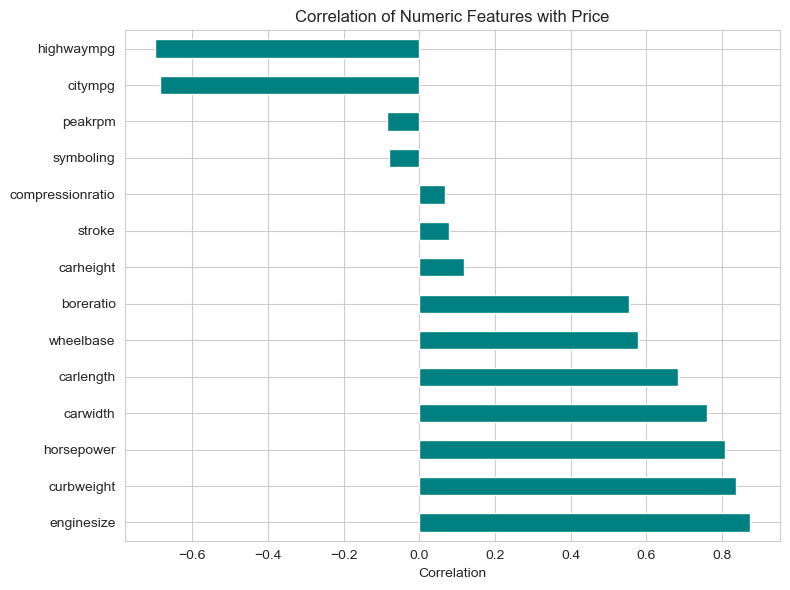

enginesize          0.874145
curbweight          0.835305
horsepower          0.808139
carwidth            0.759325
carlength           0.682920
wheelbase           0.577816
boreratio           0.553173
carheight           0.119336
stroke              0.079443
compressionratio    0.067984
symboling          -0.079978
peakrpm            -0.085267
citympg            -0.685751
highwaympg         -0.697599
Name: price, dtype: float64


In [21]:
corr_with_price = data[num_cols + ['price']].corr()['price'].drop('price').sort_values(ascending=False)

plt.figure(figsize=(8, 6))
corr_with_price.plot(kind='barh', color='teal')
plt.title('Correlation of Numeric Features with Price')
plt.xlabel('Correlation')
plt.tight_layout()
plt.show()

print(corr_with_price)

- Encode categoricals + prepare X and y

Label encoding turns each category into an integer (gas 0, diesel 1).  
Tree models handle this well. 

For Linear/SVR we also scale numeric values so large numbers (curbweight ~3000) do not dominate small ones (boreratio ~3).

In [22]:
# Label-encode all categorical columns
encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    encoders[col] = le  # keep for reference if needed later

# Features (X) and target (y)
X = data.drop(columns=['price'])
y = data['price']

feature_names = X.columns.tolist()
print('Number of features:', len(feature_names))
print(feature_names)
X.head()

Number of features: 24
['symboling', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'company']


,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,company
0,3,1,0,1,0,2,0,88.6,168.8,64.1,48.8,2548,0,2,130,5,3.47,2.68,9.0,111,5000,21,27,0
1,3,1,0,1,0,2,0,88.6,168.8,64.1,48.8,2548,0,2,130,5,3.47,2.68,9.0,111,5000,21,27,0
2,1,1,0,1,2,2,0,94.5,171.2,65.5,52.4,2823,5,3,152,5,2.68,3.47,9.0,154,5000,19,26,0
3,2,1,0,0,3,1,0,99.8,176.6,66.2,54.3,2337,3,2,109,5,3.19,3.40,10.0,102,5500,24,30,1
4,2,1,0,0,3,0,0,99.4,176.6,66.4,54.3,2824,3,1,136,5,3.19,3.40,8.0,115,5500,18,22,1


In [23]:
# Train / test split - 80% train, 20% test
# random_state makes results reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features (important for Linear Regression & SVR)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Train size:', X_train.shape[0])
print('Test size :', X_test.shape[0])

Train size: 164
Test size : 41


- Model Implementation

In [24]:
def evaluate_model(name, model, X_tr, X_te, y_tr, y_te):
    """Fit a model and return R2, MSE, MAE on the test set."""
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    return {
        'Model': name,
        'R2': r2_score(y_te, y_pred),
        'MSE': mean_squared_error(y_te, y_pred),
        'MAE': mean_absolute_error(y_te, y_pred),
        'y_pred': y_pred,
        'model': model,
    }


In [25]:
# Define the five required models
models = {
    'Linear Regression': (LinearRegression(), True),          # True = use scaled data
    'Decision Tree': (DecisionTreeRegressor(random_state=42), False),
    'Random Forest': (RandomForestRegressor(n_estimators=100, random_state=42), False),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=42), False),
    # Larger C needed because prices are in thousands (default C=1 underfits)
    'SVR': (SVR(kernel='rbf', C=10000), True),
}

results = []
fitted = {}

for name, (model, use_scaled) in models.items():
    X_tr = X_train_scaled if use_scaled else X_train
    X_te = X_test_scaled if use_scaled else X_test
    out = evaluate_model(name, model, X_tr, X_te, y_train, y_test)
    fitted[name] = out
    results.append({k: out[k] for k in ['Model', 'R2', 'MSE', 'MAE']})
    print(f"{name:20s} | R2={out['R2']:.4f} | MSE={out['MSE']:.2f} | MAE={out['MAE']:.2f}")

results_df = pd.DataFrame(results).sort_values('R2', ascending=False).reset_index(drop=True)
results_df

Linear Regression    | R2=0.8459 | MSE=12163932.55 | MAE=2090.53
Decision Tree        | R2=0.8834 | MSE=9205010.39 | MAE=2060.04
Random Forest        | R2=0.9556 | MSE=3507404.44 | MAE=1325.25
Gradient Boosting    | R2=0.9313 | MSE=5425244.70 | MAE=1628.69
SVR                  | R2=0.8675 | MSE=10462767.27 | MAE=2047.41


,Model,R2,MSE,MAE
0,Random Forest,0.955571,3.507404e+06,1325.254524
1,Gradient Boosting,0.931277,5.425245e+06,1628.694523
2,Decision Tree,0.883398,9.205010e+06,2060.040659
3,SVR,0.867466,1.046277e+07,2047.411332
4,Linear Regression,0.845917,1.216393e+07,2090.532800


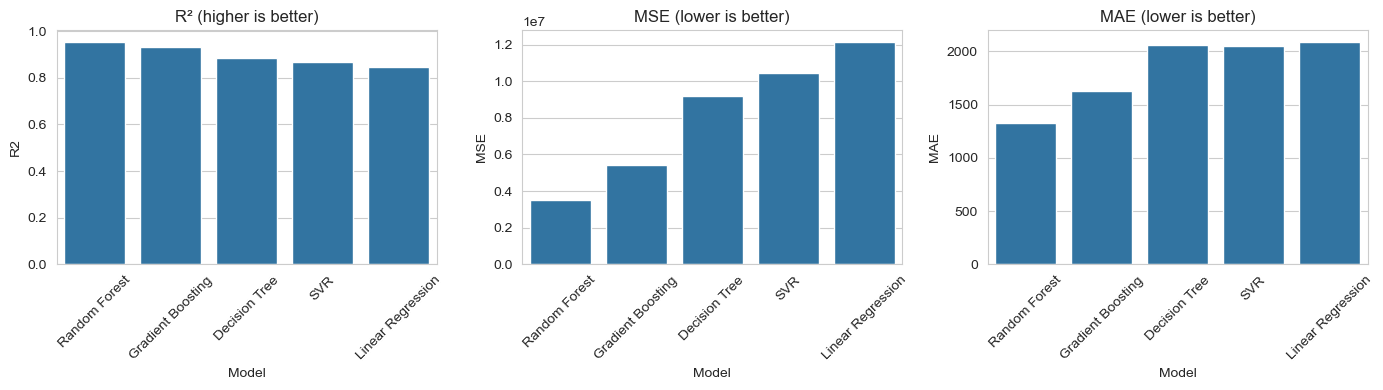

Best model by R²: Random Forest
Model     Random Forest
R2             0.955571
MSE      3507404.436785
MAE         1325.254524
Name: 0, dtype: object


In [26]:
# Comparison charts
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.barplot(data=results_df, x='Model', y='R2', ax=axes[0])
axes[0].set_title('R² (higher is better)')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(data=results_df, x='Model', y='MSE', ax=axes[1])
axes[1].set_title('MSE (lower is better)')
axes[1].tick_params(axis='x', rotation=45)

sns.barplot(data=results_df, x='Model', y='MAE', ax=axes[2])
axes[2].set_title('MAE (lower is better)')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

best_name = results_df.iloc[0]['Model']
print(f'Best model by R²: {best_name}')
print(results_df.iloc[0])

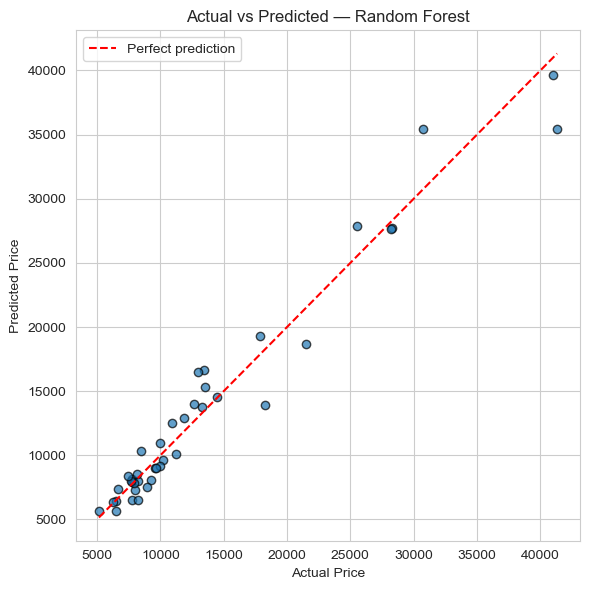

In [27]:
# Actual vs Predicted for the best model
best_pred = fitted[best_name]['y_pred']

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.7, edgecolor='k')
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title(f'Actual vs Predicted — {best_name}')
plt.legend()
plt.tight_layout()
plt.show()

- The best model is typically Random Forest

Random Forest is the best model with R^2 = 0.956, MSE = 3507404.436785, and MAE = 1325.254524.

It outperforms Gradient Boosting, Decision Tree, SVR, and Linear Regression on all three metrics.

This shows the selected features describe US car prices well, and ensemble tree methods fit this market better than a simple linear model.

- Feature Importance Analysis

Tree ensembles expose feature_importances_ : how much each variable reduced prediction error across the trees.


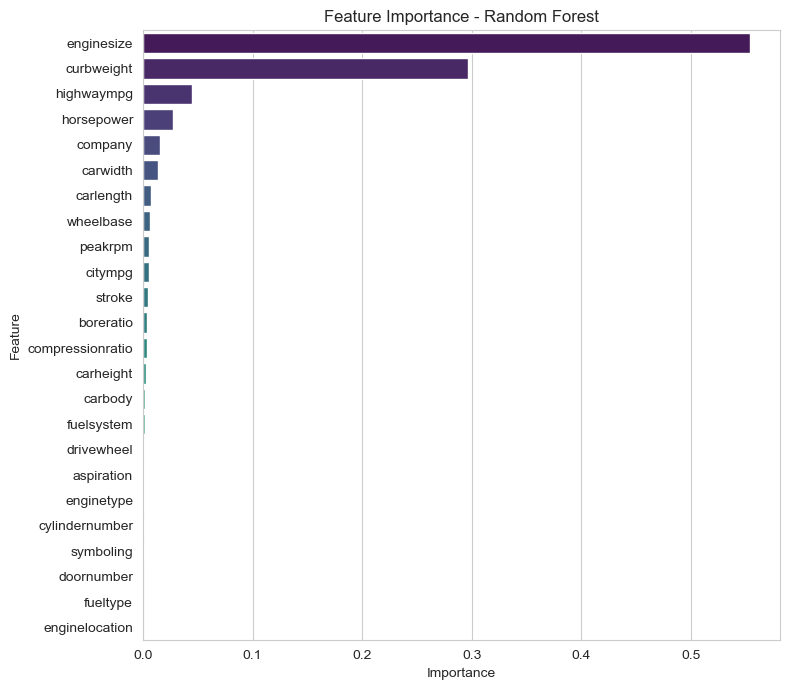

Top significant variables:
   Feature  Importance
enginesize    0.553578
curbweight    0.296789
highwaympg    0.045180
horsepower    0.027618
   company    0.015461
  carwidth    0.013467
 carlength    0.007216
 wheelbase    0.006288
   peakrpm    0.005209
   citympg    0.005120


In [28]:
# Prefer an ensemble model for importance (Random Forest or Gradient Boosting)
importance_model_name = 'Random Forest' if 'Random Forest' in fitted else best_name
imp_model = fitted[importance_model_name]['model']

if hasattr(imp_model, 'feature_importances_'):
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': imp_model.feature_importances_
    }).sort_values('Importance', ascending=False)

    plt.figure(figsize=(8, 7))
    sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
    plt.title(f'Feature Importance - {importance_model_name}')
    plt.tight_layout()
    plt.show()

    print('Top significant variables:')
    print(importance_df.head(10).to_string(index=False))
else:
    print(f'{importance_model_name} has no feature_importances_. Try Random Forest.')

- The most significant variables predicting car price are enginesize and curbweight, followed by highwaympg, horsepower, and company.
- Engine size and vehicle weight alone account for most of the model’s explanatory power, which matches the US market pattern that larger, more powerful cars command higher prices.
- Brand (company) and body dimensions matter less but still contribute.

- Hyperparameter Tuning:
- Hyperparameters are settings you choose before training (tree depth, number of trees, learning rate).
- GridSearchCV tries combinations with cross-validation and picks the best by R².
We tune the current best ensemble and compare before vs after.

In [29]:
# Baseline scores before tuning (from earlier results)
baseline = results_df[results_df['Model'] == 'Random Forest'].iloc[0]
print('Random Forest BEFORE tuning:')
print(baseline)

# Parameter grid (kept small so it runs in a few minutes on a laptop)
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
}

grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    n_jobs=-1,
    verbose=1,
)

grid.fit(X_train, y_train)

print('\nBest hyperparameters:', grid.best_params_)
print('Best CV R²:', round(grid.best_score_, 4))

Random Forest BEFORE tuning:
Model     Random Forest
R2             0.955571
MSE      3507404.436785
MAE         1325.254524
Name: 0, dtype: object
Fitting 5 folds for each of 36 candidates, totalling 180 fits

Best hyperparameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Best CV R²: 0.897


In [30]:
# Evaluate tuned model on the same test set
best_rf = grid.best_estimator_
y_pred_tuned = best_rf.predict(X_test)

tuned_metrics = {
    'Model': 'Random Forest (Tuned)',
    'R2': r2_score(y_test, y_pred_tuned),
    'MSE': mean_squared_error(y_test, y_pred_tuned),
    'MAE': mean_absolute_error(y_test, y_pred_tuned),
}

print('AFTER tuning:')
for k, v in tuned_metrics.items():
    print(f'  {k}: {v}')

print('\nImprovement check:')
print(f"  R²  : {baseline['R2']:.4f} → {tuned_metrics['R2']:.4f}")
print(f"  MSE : {baseline['MSE']:.2f} → {tuned_metrics['MSE']:.2f}")
print(f"  MAE : {baseline['MAE']:.2f} → {tuned_metrics['MAE']:.2f}")

improved = tuned_metrics['R2'] >= baseline['R2']
print('\nDid tuning improve (or match) test R²?', improved)
print('(Small datasets can show tiny gains or even slight drops on one test split — report both scores honestly.)')

AFTER tuning:
  Model: Random Forest (Tuned)
  R2: 0.9566881334391024
  MSE: 3419212.8981204457
  MAE: 1285.8435214397641

Improvement check:
  R²  : 0.9556 → 0.9567
  MSE : 3507404.44 → 3419212.90
  MAE : 1325.25 → 1285.84

Did tuning improve (or match) test R²? True
(Small datasets can show tiny gains or even slight drops on one test split — report both scores honestly.)


In [31]:
# Final scoreboard including tuned RF
final_table = results_df.copy()
final_table = pd.concat([
    final_table,
    pd.DataFrame([tuned_metrics])
], ignore_index=True).sort_values('R2', ascending=False).reset_index(drop=True)

final_table

,Model,R2,MSE,MAE
0,Random Forest (Tuned),0.956688,3.419213e+06,1285.843521
1,Random Forest,0.955571,3.507404e+06,1325.254524
2,Gradient Boosting,0.931277,5.425245e+06,1628.694523
3,Decision Tree,0.883398,9.205010e+06,2060.040659
4,SVR,0.867466,1.046277e+07,2047.411332
5,Linear Regression,0.845917,1.216393e+07,2090.532800


- Save model as joblib:
  
It saves the tuned Random Forest + encoders so we can load them in Flask.

In [33]:
import joblib
from pathlib import Path

# Folder next to this notebook
model_dir = Path("model")
model_dir.mkdir(exist_ok=True)

# Defaults for Flask form (numeric = median, categorical = most common label)
defaults = {}
for col in num_cols:
    defaults[col] = float(X[col].median())

for col in cat_cols:
    mode_encoded = int(X[col].mode().iloc[0])
    defaults[col] = encoders[col].inverse_transform([mode_encoded])[0]

# Dropdown options for categorical fields
category_options = {
    col: sorted(encoders[col].classes_.tolist()) for col in cat_cols
}

artifacts = {
    "model": best_rf,                 # tuned Random Forest
    "encoders": encoders,             # LabelEncoders for each categorical column
    "feature_names": feature_names,   # column order used in training
    "cat_cols": cat_cols,
    "num_cols": num_cols,
    "defaults": defaults,
    "category_options": category_options,
    "best_params": grid.best_params_,
}

out_path = model_dir / "car_price_artifacts.joblib"
joblib.dump(artifacts, out_path)

#print("Saved:", out_path.resolve())
print("Best params:", grid.best_params_)
print("Features:", len(feature_names))

# Quick load check
loaded = joblib.load(out_path)
print("Load OK. Model type:", type(loaded["model"]).__name__)

Best params: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Features: 24
Load OK. Model type: RandomForestRegressor
